In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from scipy.stats import ttest_ind
import scipy.stats as stats

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [23]:
from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///inventory.db")

tables = pd.read_sql_query(
    "SELECT name, type FROM sqlite_master ORDER BY type, name;",
    engine
)

print(tables)
from sqlalchemy import inspect

inspector = inspect(engine)

print("Views:")
print(inspector.get_view_names())

df = pd.read_sql_query(
    """
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
    """,
    engine
)

print(df.head())

                   name   type
0       begin_inventory  table
1         end_inventory  table
2              purchase  table
3       purchase_prices  table
4            purchases   table
5                 sales  table
6        vendor_invoice  table
7  vendor_sales_summary  table
Views:
[]
   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 18

In [24]:
from scipy.stats import ttest_ind

# Define thresholds
top_threshold = df["TotalSalesDollars"].quantile(0.85)
low_threshold = df["TotalSalesDollars"].quantile(0.15)

# Top vendors (high sales)
top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()

# Low vendors (low sales)
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

# Perform Welch's t-test
t_stat, p_value = ttest_ind(
    top_vendors,
    low_vendors,
    equal_var=False
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Significant difference in profit margins.")
else:
    print("No significant difference in profit margins.")

T-statistic: -11.7633
P-value: 0.0000
Significant difference in profit margins.


In [49]:
#summary Statistics
summary_stats = df.describe(include='all').T

# Sort by column name for readability
summary_stats = summary_stats.sort_index()

display(summary_stats)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ActualPrice,8564.0,NaN,NaN,NaN,32.297467,112.420744,0.49,9.99,14.99,25.99,4559.99
Brand,8564.0,NaN,NaN,NaN,17614.670131,12946.130933,58.0,5375.75,17606.0,24935.25,90631.0
Description,8564,7707,Southern Comfort,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FreightCost,8564.0,NaN,NaN,NaN,63449.647583,62268.879503,0.09,14836.57,55551.82,89286.27,257032.07
GrossProfit,8564.0,NaN,NaN,NaN,15655.024752,51004.186873,0.04,491.8,3087.05,12461.18,1290667.91
ProfitMargin,8564.0,NaN,NaN,NaN,38.722987,21.374008,0.020842,25.930013,33.358949,44.124763,99.716657
PurchasePrice,8564.0,NaN,NaN,NaN,21.780897,81.189624,0.36,6.66,10.06,17.85,3352.93
SalesToPurchaseRatio,8564.0,NaN,NaN,NaN,2.991425,9.387282,1.000208,1.350074,1.500577,1.789702,352.928571
StockTurnover,8564.0,NaN,NaN,NaN,2.032054,6.686248,0.428571,0.945265,1.0,1.120683,274.5
TotalExciseTax,8564.0,NaN,NaN,NaN,2182.808183,12225.917775,0.1,9.45,84.81,594.775,368242.8


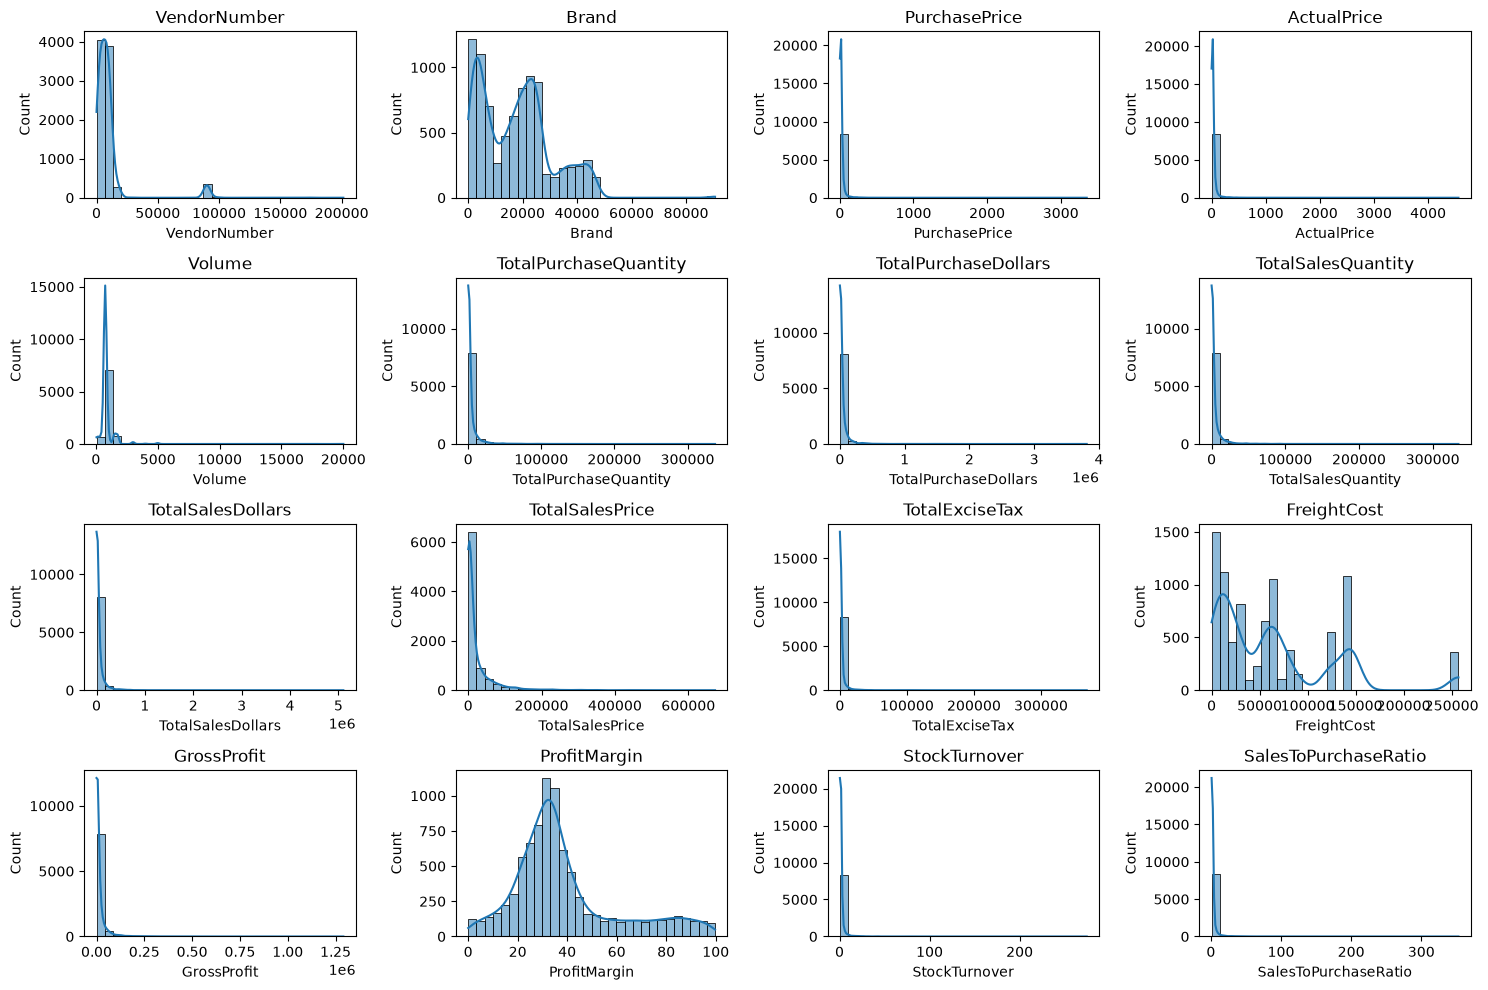

In [46]:
#Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize =(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Adjust grid layout as needed
    sns.histplot(df[col],kde= True,bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

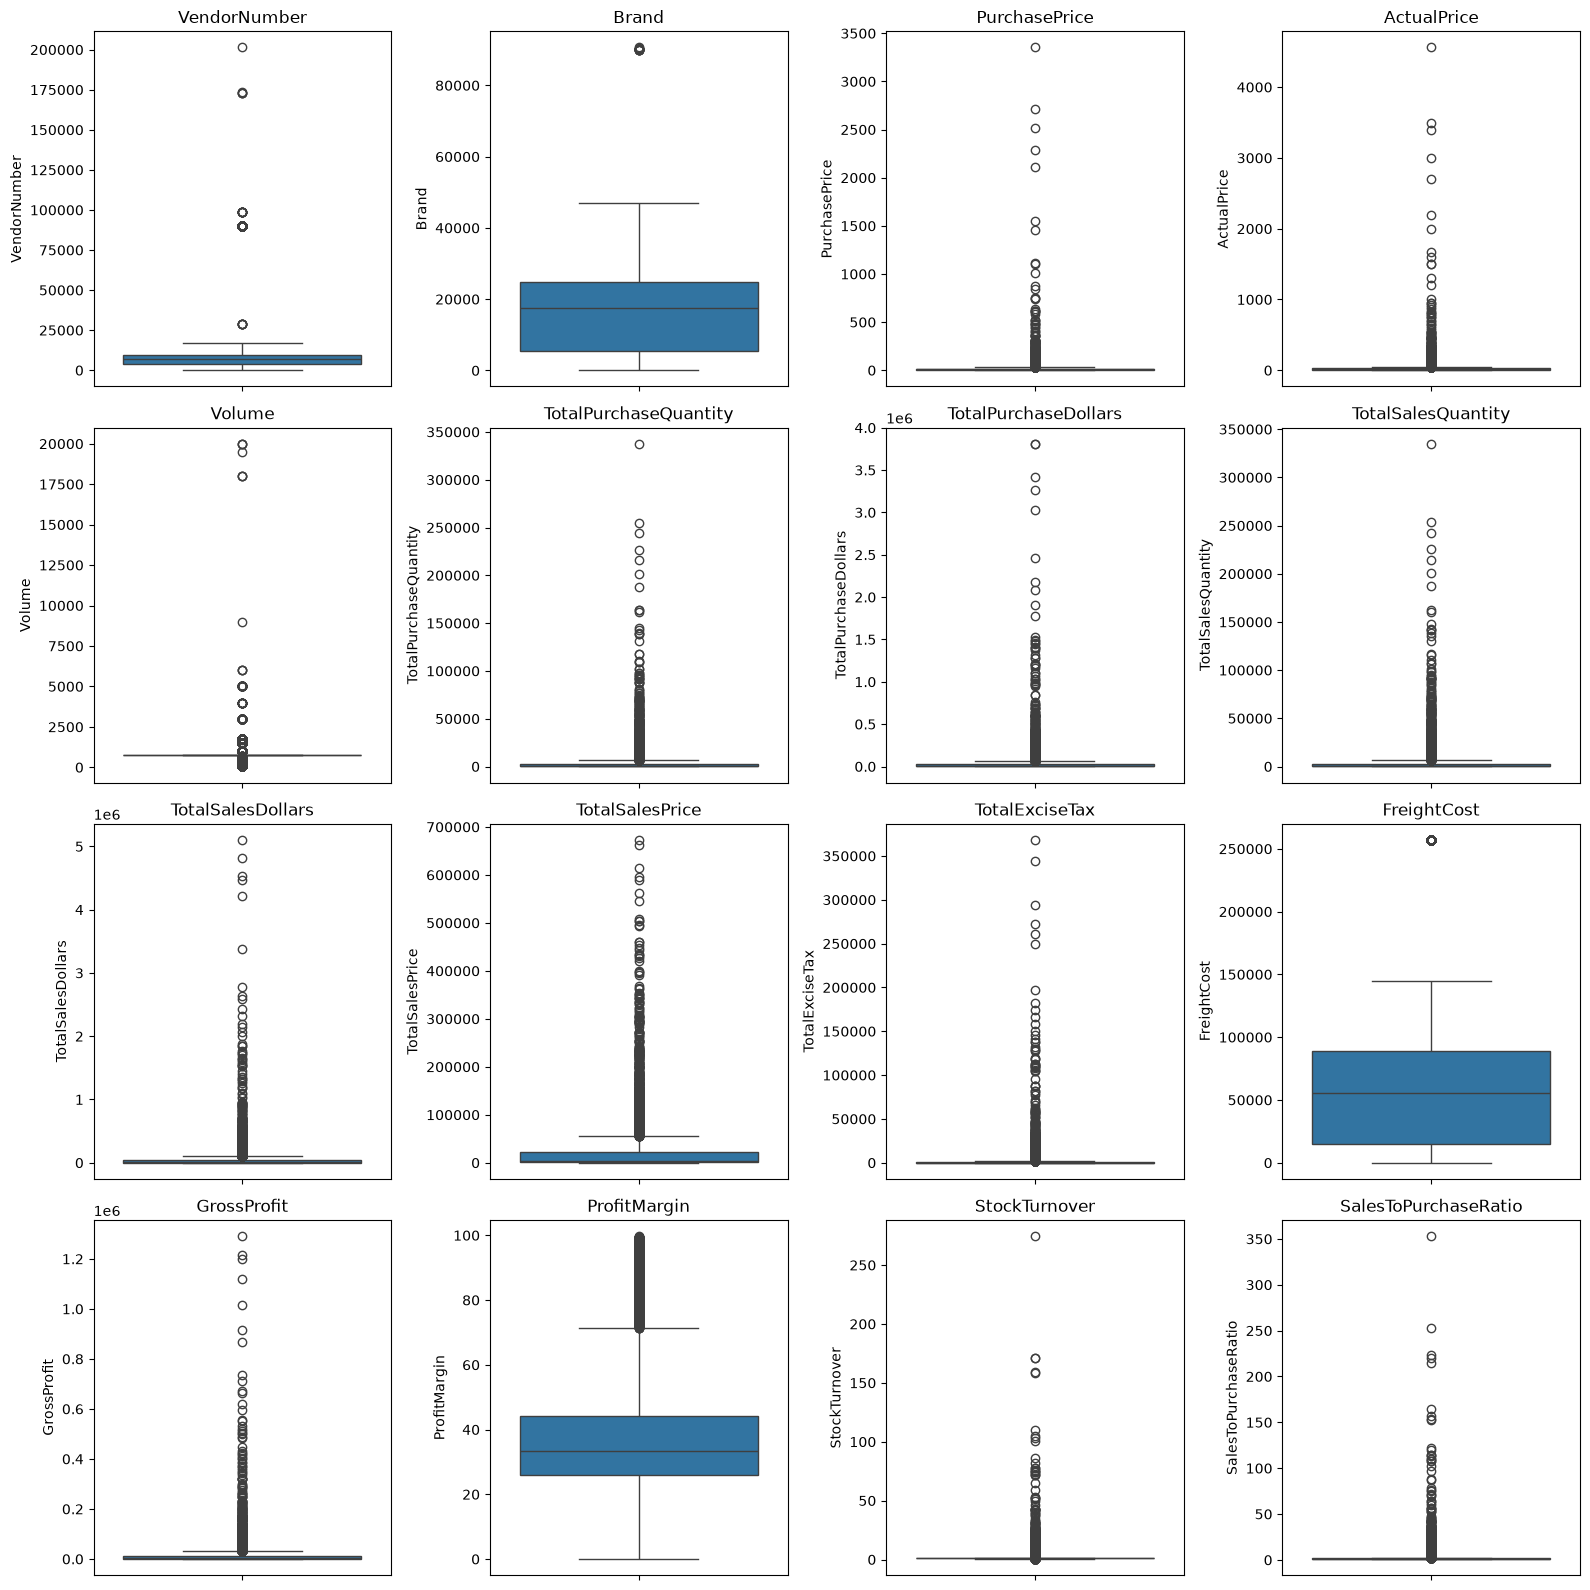

In [45]:
# Outlier Detection with Boxplots

import math

numerical_cols = df.select_dtypes(include='number').columns

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

plt.figure(figsize=(16, 4 * n_rows))

for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()  

In [41]:
# let`s filter the data by removing inconsistencies
df = pd.read_sql_query("""
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
      AND ProfitMargin > 0
      AND TotalSalesQuantity > 0
""", engine)
print(pd.read_sql_query(
    "PRAGMA table_info(vendor_sales_summary)",
    engine
))


    cid                   name    type  notnull dflt_value  pk
0     0           VendorNumber  BIGINT        0       None   0
1     1             VendorName    TEXT        0       None   0
2     2                  Brand  BIGINT        0       None   0
3     3            Description    TEXT        0       None   0
4     4          PurchasePrice   FLOAT        0       None   0
5     5            ActualPrice   FLOAT        0       None   0
6     6                 Volume   FLOAT        0       None   0
7     7  TotalPurchaseQuantity  BIGINT        0       None   0
8     8   TotalPurchaseDollars   FLOAT        0       None   0
9     9     TotalSalesQuantity   FLOAT        0       None   0
10   10      TotalSalesDollars   FLOAT        0       None   0
11   11        TotalSalesPrice   FLOAT        0       None   0
12   12         TotalExciseTax   FLOAT        0       None   0
13   13            FreightCost   FLOAT        0       None   0
14   14            GrossProfit   FLOAT        0       N

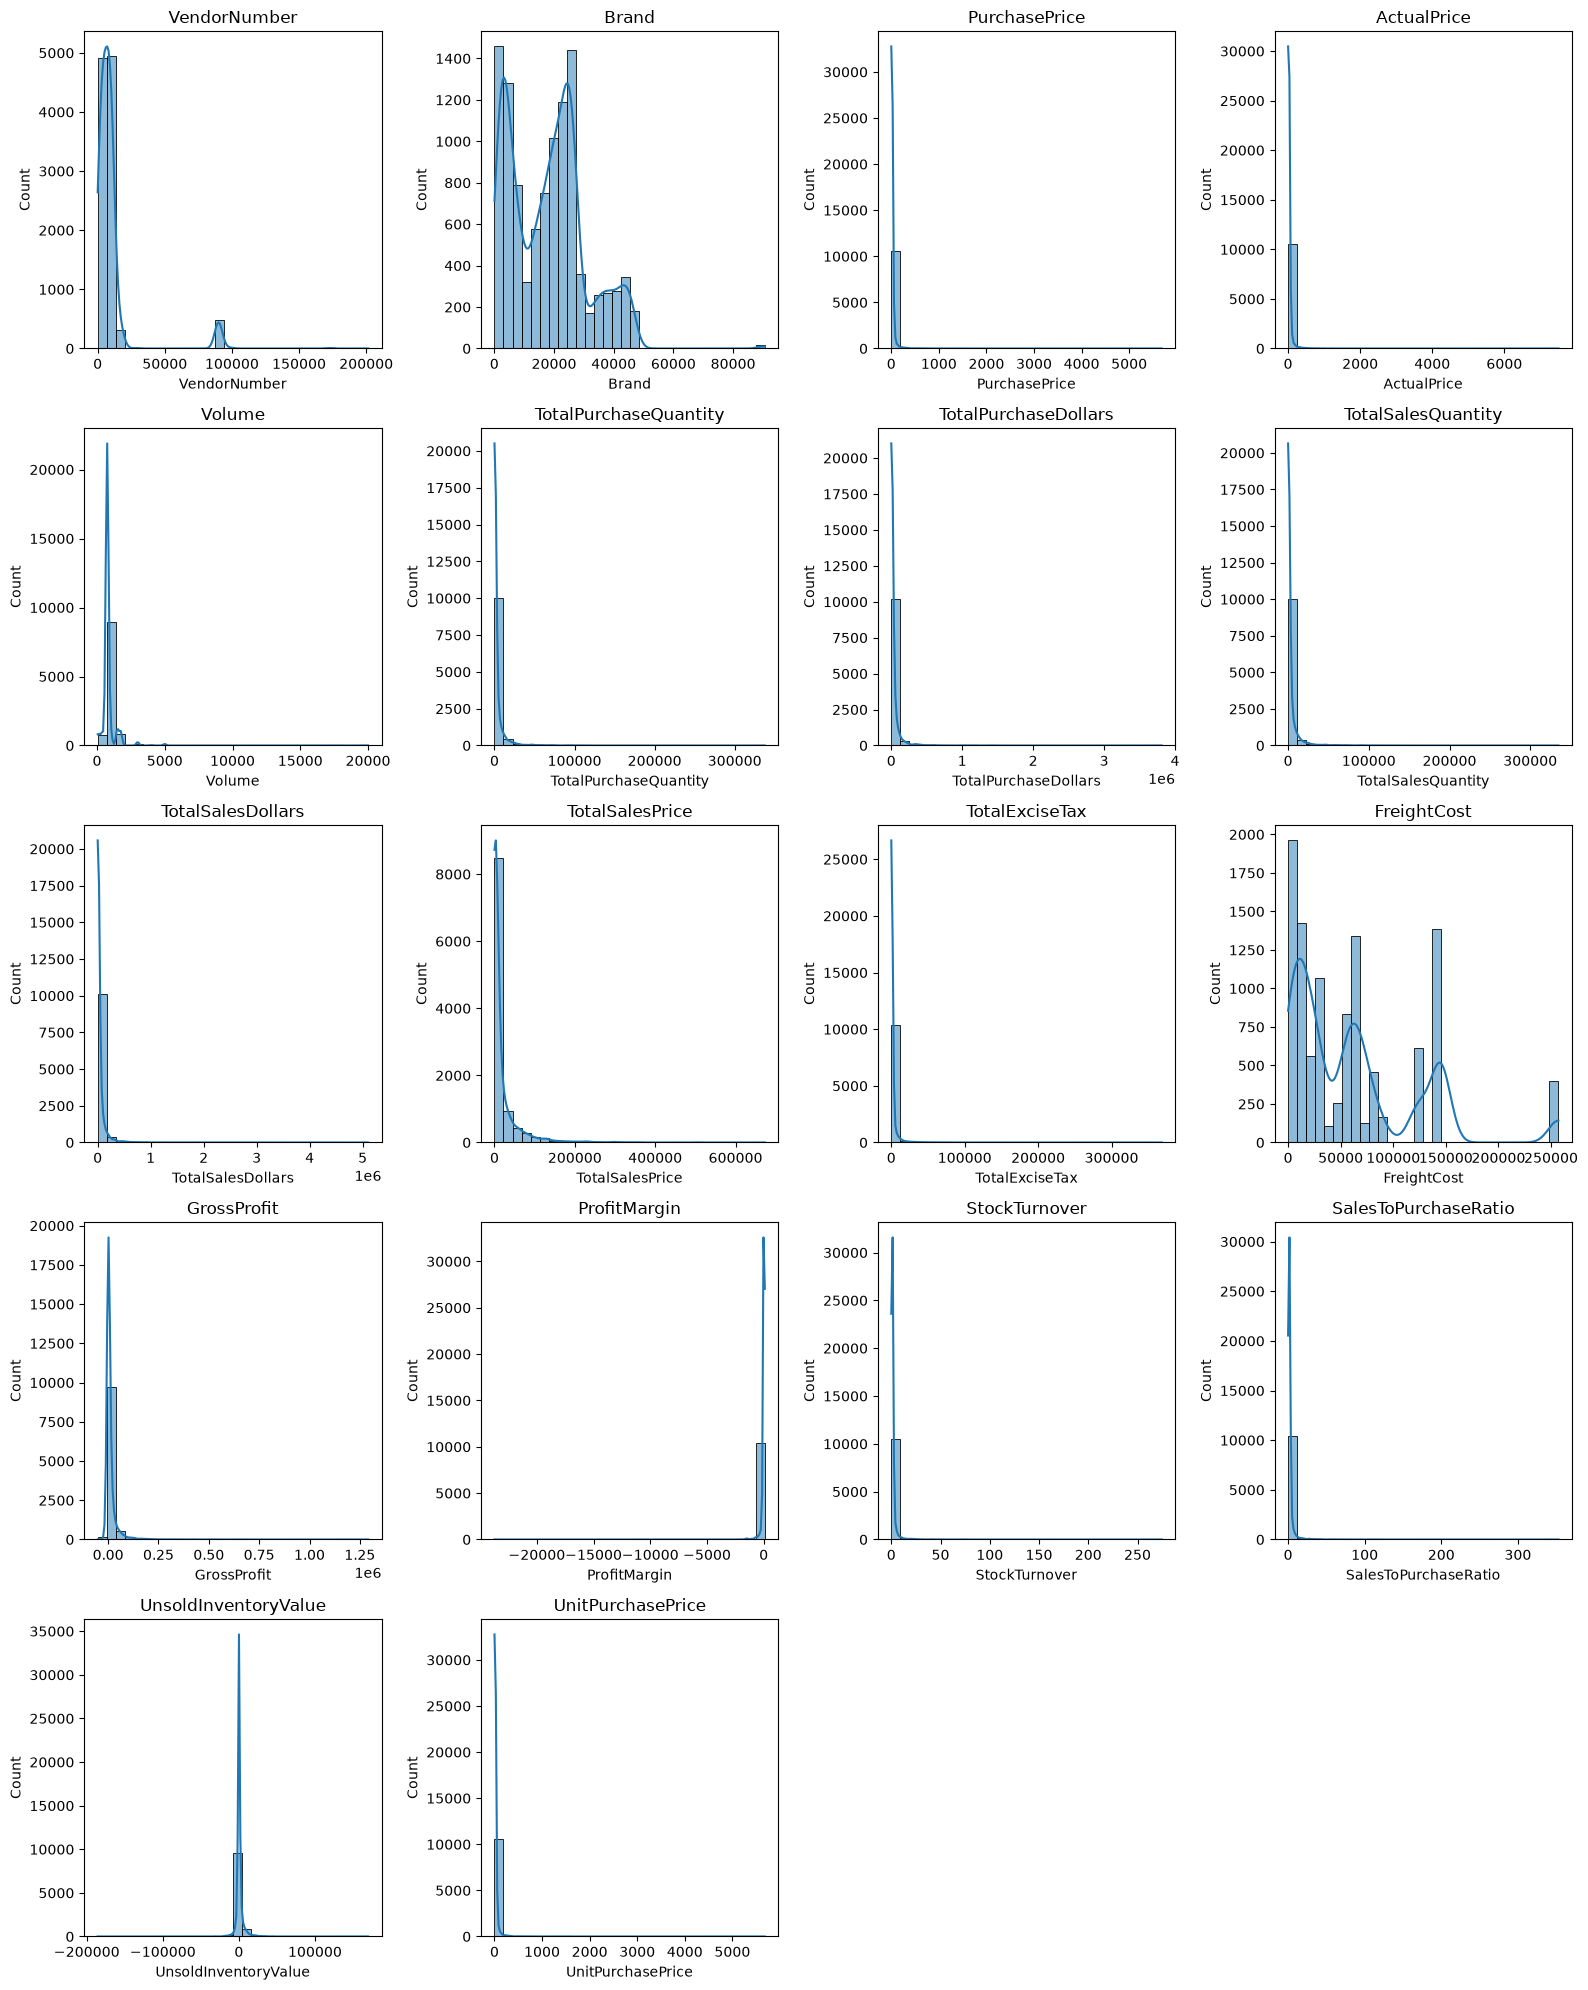

In [39]:
#Distribution Plots for Numerical Columns
import math

numerical_cols = df.select_dtypes(include=np.number).columns

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

plt.figure(figsize=(16, 4 * n_rows))

for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1)

    sns.histplot(
        df[col],
        kde=True,
        bins=30
    )

    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
# count plot for Categorical Columns

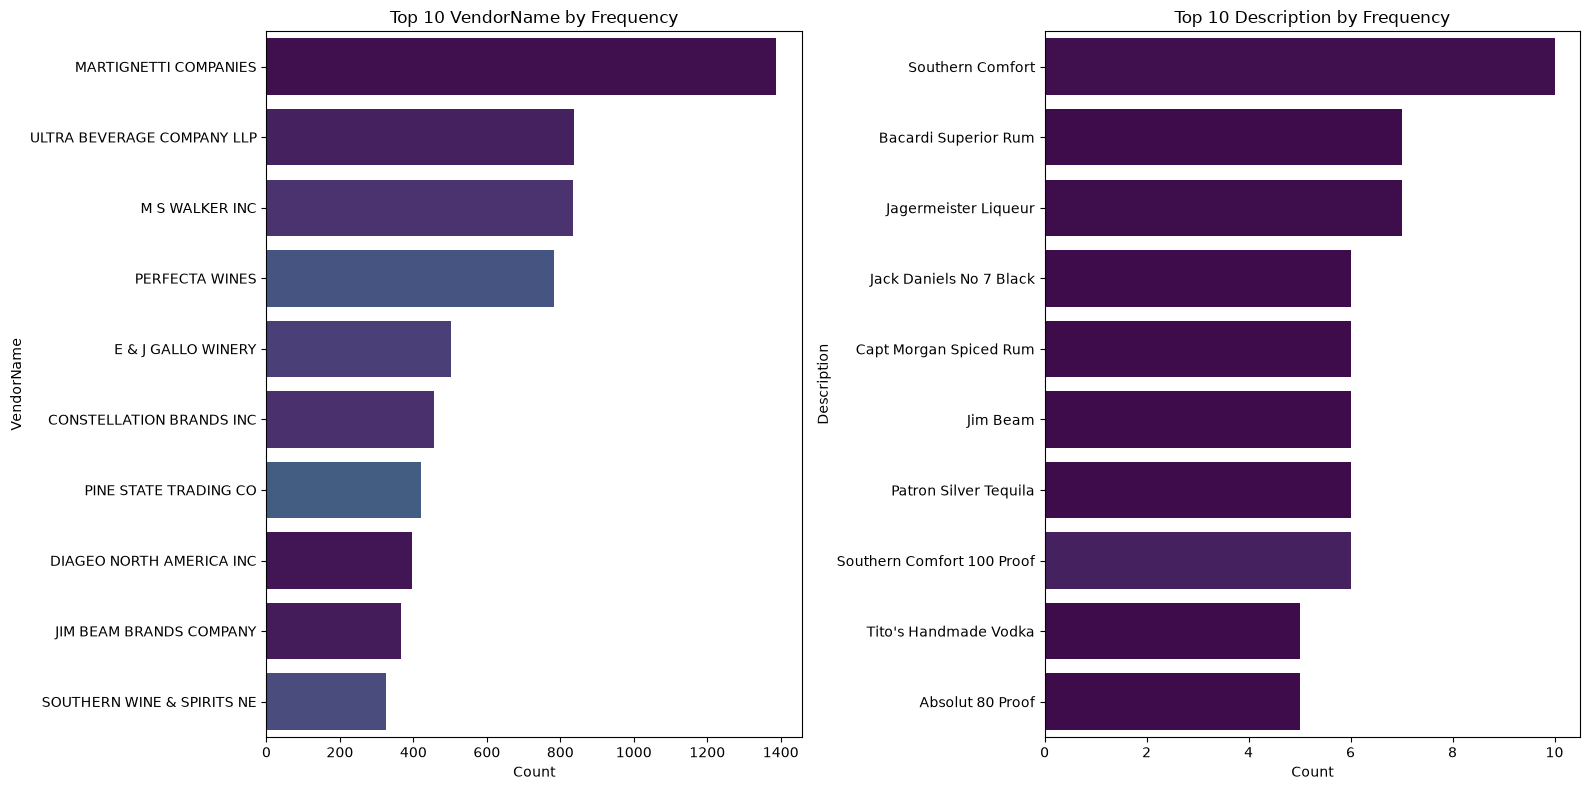

In [36]:
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(16, 8))

for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)

    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().head(10).index,
        hue=col,
        palette="viridis",
        legend=False
    )

    plt.title(f"Top 10 {col} by Frequency")
    plt.xlabel("Count")
    plt.ylabel(col)

plt.tight_layout()
plt.show()          

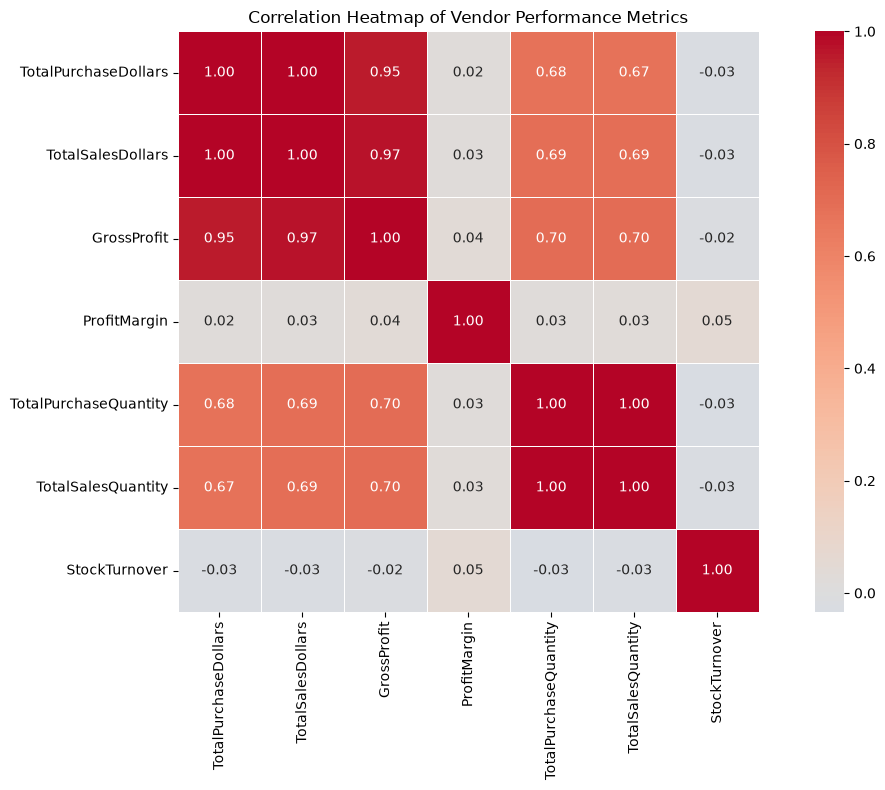

In [37]:
# Corealtion Heatmap

numerical_cols = [
    'TotalPurchaseDollars',
    'TotalSalesDollars',
    'GrossProfit',
    'ProfitMargin',
    'TotalPurchaseQuantity',
    'TotalSalesQuantity',
    'StockTurnover'
]
plt.figure(figsize =(12,8))
correlation_matrix=df[numerical_cols].corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Vendor Performance Metrics")
plt.tight_layout()
plt.show()

In [ ]:
#Identify Brands that needs Promotional or Pricing Adjustments which exibit lower sales performance but higher profits margins

In [31]:
# Filter Brands with low sales but high profit margins
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.25)

high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.75)





target_brands = brand_performance[
    (brand_performance['TotalSalesDollars']<= low_sales_threshhold) &
    (brand_performance['ProfitMargin']>= high_margin_threshhold)
]
print("Brands with Low Sales but High Profit Margins")
display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins
       Brand  TotalSalesDollars  TotalPurchaseDollars  GrossProfit  \
10399  44733           10012.67               6077.49      3935.18   
9888   39600           10054.28               6124.46      3929.82   
1627    3404           10058.93               3732.40      6326.53   
9421   34635           10190.24               6014.73      4175.51   
10110  42124           10199.85               5390.91      4808.94   
...      ...                ...                   ...          ...   
3371    8567           19428.20              11940.75      7487.45   
7596   24703           19432.84               9906.06      9526.78   
2880    6566           19490.49              10260.88      9229.61   
847     2050           19502.42              10566.93      8935.49   
5186   18332           19595.37              12002.76      7592.61   

       ProfitMargin  
10399     39.302004  
9888      39.086041  
1627      62.894662  
9421      40.975581  
101

In [29]:
brand_performance = (
df.groupby('Brand')
.agg({
'TotalSalesDollars': 'sum',
'TotalPurchaseDollars': 'sum',
'GrossProfit': 'sum',
'ProfitMargin': 'mean'
})
.reset_index()
)
brand_performance = brand_performance[
    brand_performance['TotalSalesDollars'] > 10000
]

print(brand_performance.shape)
brand_performance.head()

(4308, 5)


,Brand,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
0,58,43341.54,32944.00,10397.54,23.989780
1,60,18716.25,12084.20,6632.05,35.434716
3,62,119863.75,91744.00,28119.75,23.459762
4,63,112249.22,86963.30,25285.92,22.526589
6,72,17325.31,11932.27,5393.04,31.128101


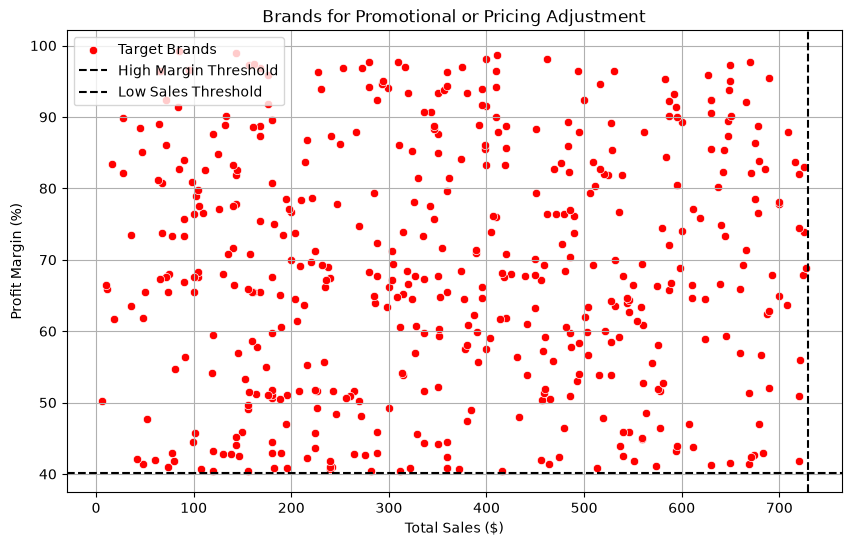

In [28]:
high_margin_threshold = df['ProfitMargin'].quantile(0.75)
low_sales_threshold = df['TotalSalesDollars'].quantile(0.25)

target_brands = df[
    (df['ProfitMargin'] >= high_margin_threshold) &
    (df['TotalSalesDollars'] <= low_sales_threshold)
]

plt.figure(figsize=(10, 6))
 
sns.scatterplot(
data=target_brands,
x='TotalSalesDollars',
y='ProfitMargin',
color='red',
label='Target Brands'
)
 
plt.axhline(
high_margin_threshold,
linestyle='--',
color='black',
label='High Margin Threshold'
)
 
plt.axvline(
low_sales_threshold,
linestyle='--',
color='black',
label='Low Sales Threshold'
)
 
plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustment")
plt.legend()
plt.grid(True)
 
plt.show()


In [20]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")

vendor_sales_summary = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(vendor_sales_summary.head())

top_vendors = (
    vendor_sales_summary
    .groupby("VendorName")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)

print(top_vendors)

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(df.shape)
print(df.columns)
# Top Vendors & Brands by Sales Performance
top_vendors = (
    df.groupby("VendorName")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)
top_brands = (
    df.groupby("Description")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)
top_vendors

   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 187407   
3          16.17        22.99  1750.0                 201682   
4          21.89        29.99  1750.0                 138109   

   TotalPurchaseDollars  TotalSalesQuantity  TotalSalesDollars  \
0            3811251.60            142049.0         5101919.51   
1            3804041

VendorName
DIAGEO NORTH AMERICA INC      68739834.97
MARTIGNETTI COMPANIES         40960117.82
PERNOD RICARD USA             32279544.17
JIM BEAM BRANDS COMPANY       31898621.16
BACARDI USA INC               25005365.79
CONSTELLATION BRANDS INC      24467134.23
E & J GALLO WINERY            18553774.66
BROWN-FORMAN CORP             18476611.60
ULTRA BEVERAGE COMPANY LLP    17802646.10
M S WALKER INC                15436066.26
Name: TotalSalesDollars, dtype: float64

In [22]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value/1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value/1_000:.2f}K"
    else:
        return f"${value:.2f}"

top_brands.apply(format_dollars)

Description
Jack Daniels No 7 Black    $7.96M
Tito's Handmade Vodka      $7.40M
Grey Goose Vodka           $7.21M
Capt Morgan Spiced Rum     $6.36M
Absolut 80 Proof           $6.24M
Jameson Irish Whiskey      $5.72M
Ketel One Vodka            $5.07M
Baileys Irish Cream        $4.15M
Kahlua                     $3.60M
Tanqueray                  $3.46M
Name: TotalSalesDollars, dtype: str

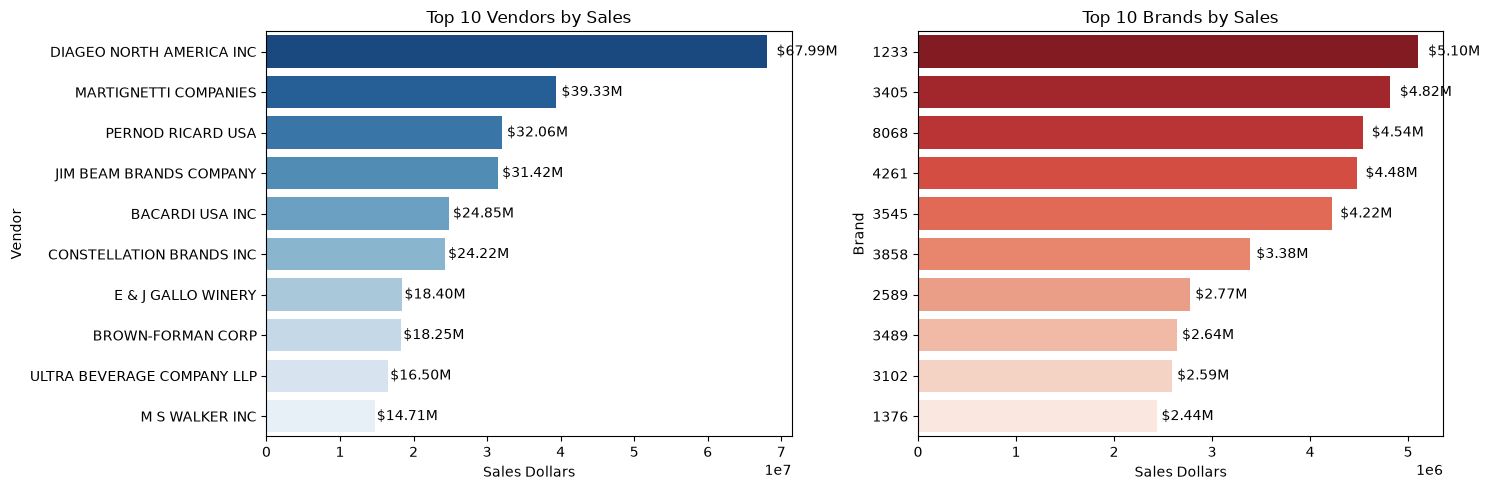

In [27]:
top_vendors = (
    df.groupby("VendorName")["TotalSalesDollars"]
      .sum()
      .nlargest(10)
)

top_brands = (
    df.groupby("Brand")["TotalSalesDollars"]
      .sum()
      .nlargest(10)
)

plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index.astype(str),
    x=top_vendors.values,
    hue=top_vendors.index.astype(str),
    palette="Blues_r",
    legend=False
)

plt.title("Top 10 Vendors by Sales")
plt.xlabel("Sales Dollars")
plt.ylabel("Vendor")

for bar in ax1.patches:
    ax1.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center"
    )

# Plot for Top Brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index.astype(str),
    x=top_brands.values,
    hue=top_brands.index.astype(str),
    palette="Reds_r",
    legend=False
)

plt.title("Top 10 Brands by Sales")
plt.xlabel("Sales Dollars")
plt.ylabel("Brand")

for bar in ax2.patches:
    ax2.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center",
        fontsize=10,
        color="black"
    )

plt.tight_layout()
plt.show()

In [25]:
# Display Top 10 Vendors

vendor_performance = (
    df.groupby('VendorName')
      .agg({
          'TotalSalesDollars': 'sum',
          'TotalPurchaseDollars': 'sum',
          'GrossProfit': 'sum'
      })
      .reset_index()
      .sort_values('TotalSalesDollars', ascending=False)
)

vendor_performance = (
    df.groupby('VendorName', as_index=False)
      .agg({
          'TotalSalesDollars': 'sum',
          'TotalPurchaseDollars': 'sum',
          'GrossProfit': 'sum'
      })
      .sort_values('TotalSalesDollars', ascending=False)
)
# Keep numeric columns unchanged
top_vendors = vendor_performance.head(10).copy()

top_vendors_display = top_vendors.copy()

for col in [
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'GrossProfit'
]:
    top_vendors_display[col] = top_vendors_display[col].apply(format_dollars)

top_vendors_display

,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit
28,DIAGEO NORTH AMERICA INC,$68.74M,$50.96M,$17.78M
63,MARTIGNETTI COMPANIES,$40.96M,$27.86M,$13.10M
74,PERNOD RICARD USA,$32.28M,$24.12M,$8.16M
50,JIM BEAM BRANDS COMPANY,$31.90M,$24.20M,$7.70M
8,BACARDI USA INC,$25.01M,$17.62M,$7.38M
23,CONSTELLATION BRANDS INC,$24.47M,$15.57M,$8.89M
33,E & J GALLO WINERY,$18.55M,$12.29M,$6.26M
14,BROWN-FORMAN CORP,$18.48M,$13.53M,$4.95M
114,ULTRA BEVERAGE COMPANY LLP,$17.80M,$13.21M,$4.59M
59,M S WALKER INC,$15.44M,$10.94M,$4.50M


In [23]:
top_vendors['PurchaseContribution%'].sum()

np.float64(65.3345754408899)

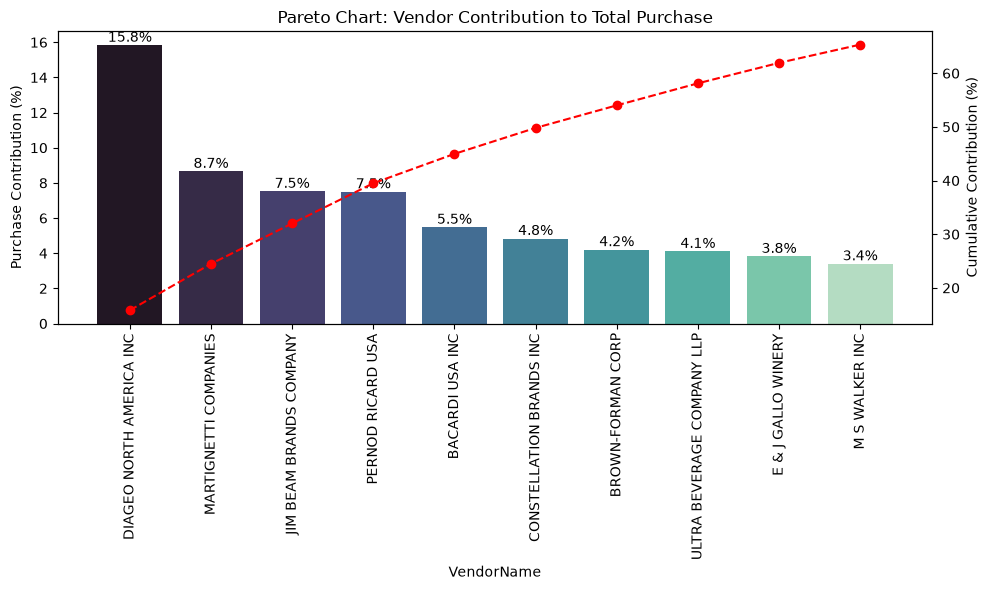

In [22]:
top_vendors = top_vendors.sort_values(
    'PurchaseContribution%',
    ascending=False
)

top_vendors['CumulativeContribution%'] = (
    top_vendors['PurchaseContribution%'].cumsum()
)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar Plot
sns.barplot(
    data=top_vendors,
    x='VendorName',
    y='PurchaseContribution%',
    hue='VendorName',
    palette='mako',
    legend=False,
    ax=ax1
)

# Add labels
for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(
        i,
        value + 0.2,
        f"{value:.1f}%",
        ha='center',
        fontsize=10
    )

# Line Plot
ax2 = ax1.twinx()

ax2.plot(
    top_vendors['VendorName'],
    top_vendors['CumulativeContribution%'],
    color='red',
    marker='o',
    linestyle='dashed'
)

plt.setp(ax1.get_xticklabels(), rotation=90)

ax1.set_ylabel('Purchase Contribution (%)')
ax2.set_ylabel('Cumulative Contribution (%)')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchase')

plt.tight_layout()
plt.show()


In [21]:
print(
    f"Total Purchase Contribution of Top 10 Vendors is "
    f"{top_vendors['PurchaseContribution%'].sum():.2f}%"
)

Total Purchase Contribution of Top 10 Vendors is 65.33%


Columns:
['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'VendorNumber', 'VendorName', 'PONumber', 'PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification']

Top 10 Vendors:
                      VendorName  TotalPurchaseDollars  Purchase_Contribution%
28   DIAGEO NORTH AMERICA INC              50959796.85               15.830903
63         MARTIGNETTI COMPANIES           27821473.91                8.642873
50   JIM BEAM BRANDS COMPANY               24203151.05                7.518824
75   PERNOD RICARD USA                     24124091.56                7.494263
8    BACARDI USA INC                       17624378.72                5.475097
23   CONSTELLATION BRANDS INC              15573917.90                4.838111
14   BROWN-FORMAN CORP                     13529433.08                4.202983
115  ULTRA BEVERAGE COMPANY LLP            13210613.93                4.103940
33   E & J GALLO WINERY                    12289608.0

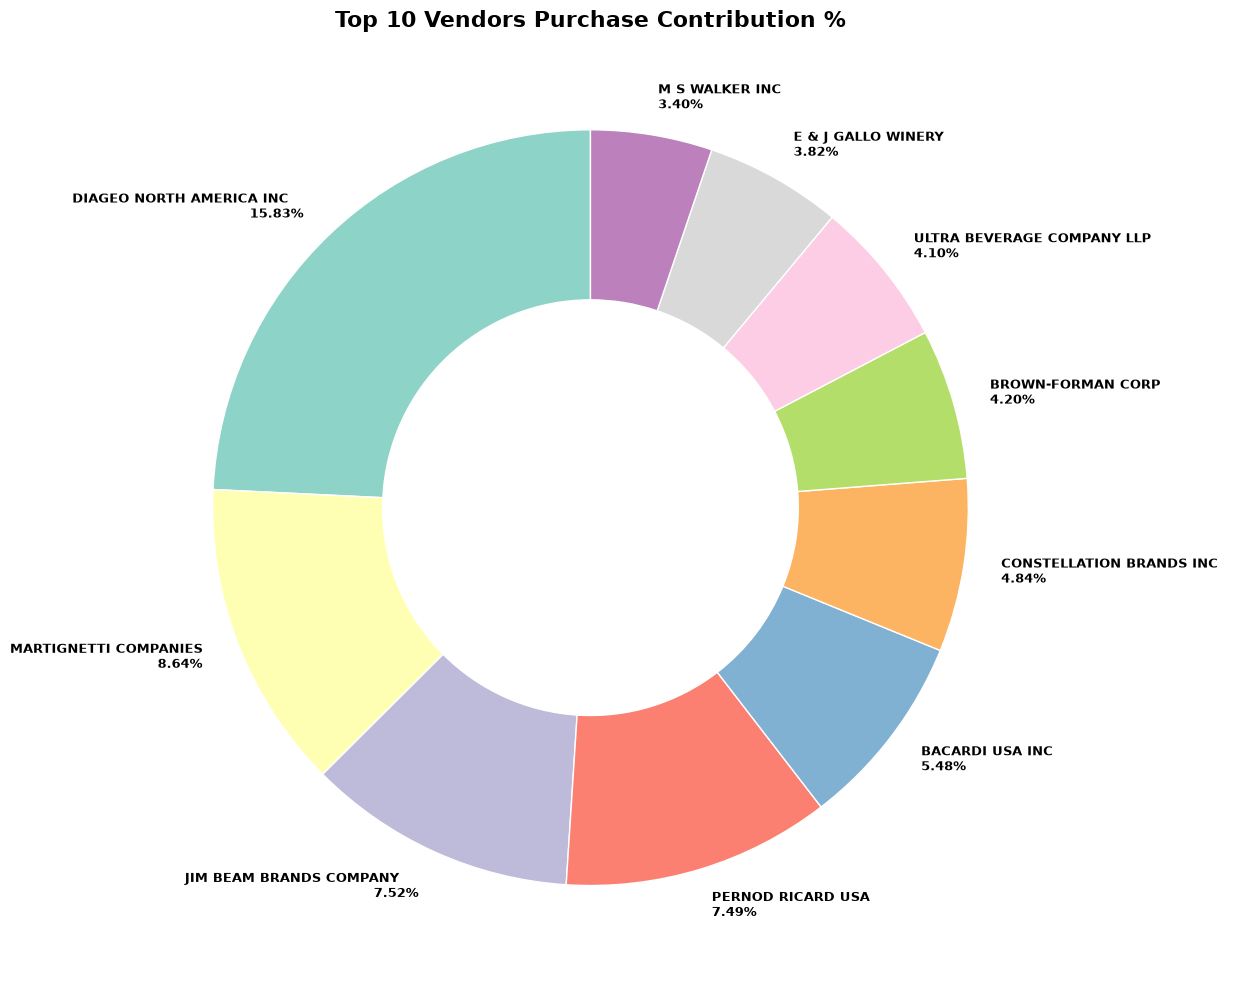

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Purchase Data
purchase_df = pd.read_csv(
    "Data/purchase.csv",
    low_memory=False
)

# Check columns
print("Columns:")
print(purchase_df.columns.tolist())

# Convert Dollars column to numeric
purchase_df["Dollars"] = pd.to_numeric(
    purchase_df["Dollars"],
    errors="coerce"
)

# Remove null values
purchase_df = purchase_df.dropna(
    subset=["VendorName", "Dollars"]
)

# Vendor Purchase Summary
vendor_purchase = (
    purchase_df
    .groupby("VendorName", as_index=False)
    .agg(
        TotalPurchaseDollars=("Dollars", "sum")
    )
)

# Total Purchase Amount
total_purchase = vendor_purchase["TotalPurchaseDollars"].sum()

if total_purchase <= 0:
    raise ValueError(
        "Total purchase amount is zero. Cannot calculate contribution percentages."
    )

# Calculate Contribution %
vendor_purchase["Purchase_Contribution%"] = (
    vendor_purchase["TotalPurchaseDollars"]
    / total_purchase
    * 100
)

# Top 10 Vendors
top_vendors = (
    vendor_purchase
    .sort_values(
        by="Purchase_Contribution%",
        ascending=False
    )
    .head(10)
)

print("\nTop 10 Vendors:")
print(top_vendors)

# -----------------------------
# Donut Chart
# -----------------------------

plt.figure(figsize=(14, 10))

labels = [
    f"{vendor}\n{pct:.2f}%"
    for vendor, pct in zip(
        top_vendors["VendorName"],
        top_vendors["Purchase_Contribution%"]
    )
]

colors = plt.cm.Set3(range(len(top_vendors)))

wedges, texts = plt.pie(
    top_vendors["Purchase_Contribution%"],
    labels=labels,
    colors=colors,
    startangle=90,
    wedgeprops=dict(
        width=0.45,
        edgecolor="white"
    ),
    textprops=dict(
        fontsize=9,
        weight="bold"
    )
)

# Donut Hole
centre_circle = plt.Circle(
    (0, 0),
    0.55,
    fc="white"
)

plt.gca().add_artist(centre_circle)

plt.title(
    "Top 10 Vendors Purchase Contribution %",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [19]:
(
    df.groupby('OrderSize', observed=True)['UnitPurchasePrice']
      .agg(['mean', 'median', 'min', 'max'])
)

,mean,median,min,max
OrderSize,,,,
Small,40.062349,12.325,0.39,5681.81
Medium,17.719004,11.250,0.71,240.59
Large,11.393655,8.660,0.36,139.70


In [18]:
df.groupby("OrderSize", observed=True)["TotalPurchaseQuantity"].agg(
    ["min", "max", "mean", "count"]
)

,min,max,mean,count
OrderSize,,,,
Small,1,100,31.392264,4214
Medium,101,1000,408.024467,2861
Large,1001,337660,8925.274260,3617


In [17]:
print(df[['OrderSize', 'TotalPurchaseQuantity']].head(10))

  OrderSize  TotalPurchaseQuantity
0     Large                 145080
1     Large                 164038
2     Large                 187407
3     Large                 201682
4     Large                 138109
5     Large                 138809
6     Large                  70783
7     Large                 161386
8     Large                  91835
9     Large                 108866


In [15]:
order_size_analysis = (
    df.groupby('OrderSize', observed=True)['UnitPurchasePrice']
      .mean()
      .sort_values()
)

print(order_size_analysis)

OrderSize
Large     11.393655
Medium    17.719004
Small     40.062349
Name: UnitPurchasePrice, dtype: float64


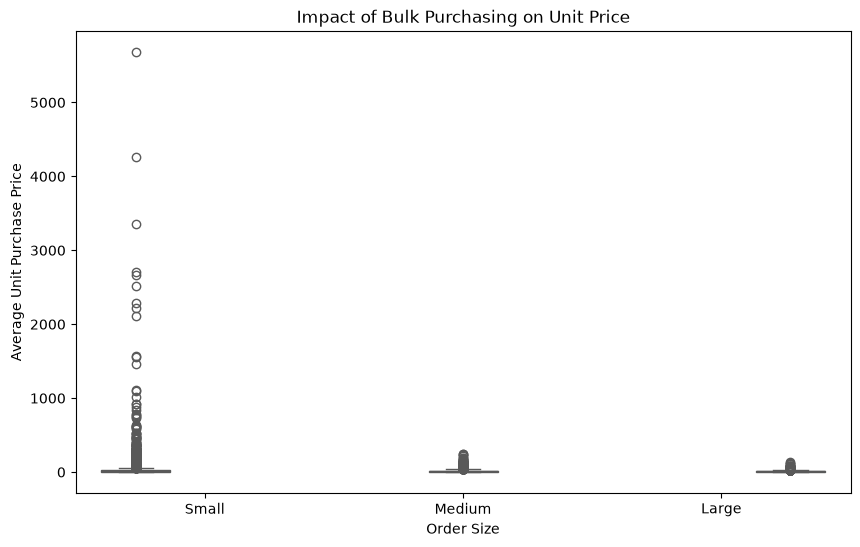

In [14]:
df["OrderSize"] = pd.cut(
    df["TotalPurchaseQuantity"],
    bins=[0, 100, 1000, float("inf")],
    labels=["Small", "Medium", "Large"]
)

df["UnitPurchasePrice"] = (
    df["TotalPurchaseDollars"] / df["TotalPurchaseQuantity"]
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="OrderSize",
    y="UnitPurchasePrice",
    hue="OrderSize",
    palette="Set2",
    legend=False
)

plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()

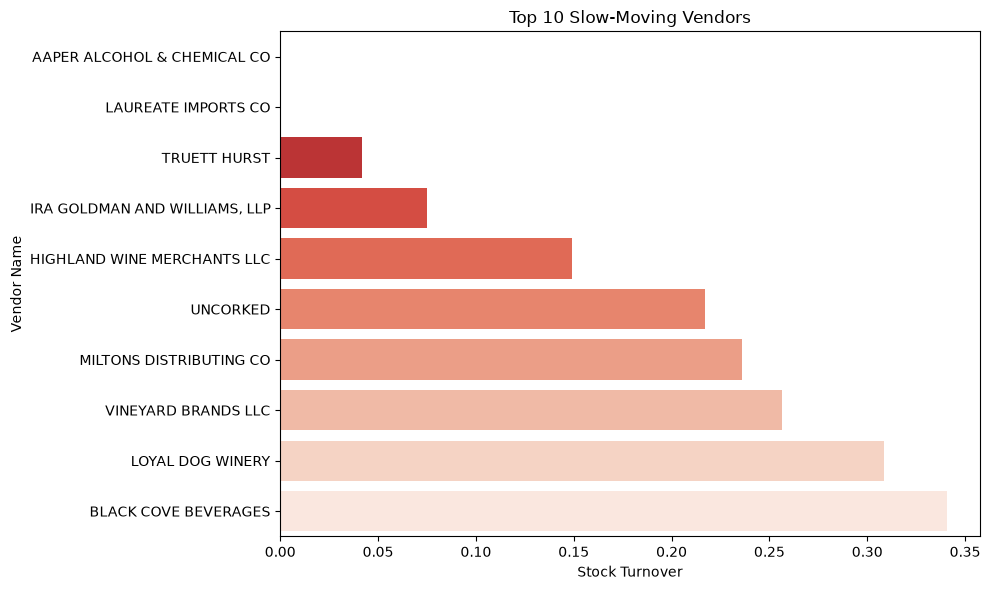

In [13]:
plot_df = (
    df[df['StockTurnover'] < 1]
    .groupby('VendorName')['StockTurnover']
    .mean()
    .sort_values()
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x='StockTurnover',
    y='VendorName',
    hue='VendorName',
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 Slow-Moving Vendors')
plt.xlabel('Stock Turnover')
plt.ylabel('Vendor Name')
plt.tight_layout()
plt.show()

In [11]:
# How much capital is locked in unsold inventory?

from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///inventory.db")

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return f"${value:.2f}"


df["UnsoldInventoryValue"] = (
    (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"])
    * df["PurchasePrice"]
)

print(
    "Total Unsold Capital:",
    format_dollars(df["UnsoldInventoryValue"].sum())
)


Total Unsold Capital: $8.75M


In [6]:
df["UnsoldQuantity"] = (
    df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]
)
df["UnsoldInventoryValue"] = (
    df["UnsoldQuantity"] * df["PurchasePrice"]
)

def format_dollars(value):
    if pd.isna(value):
        return "0"

    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return f"${value:.2f}"

inventory_value_per_vendor["UnsoldInventoryValue"] = (
    inventory_value_per_vendor["UnsoldInventoryValue"]
    .apply(format_dollars)
)


# Aggregate Capital Locked Per Vendor
inventory_value_per_vendor = (
    df.groupby("VendorName")["UnsoldInventoryValue"]
      .sum()
      .reset_index()
)

# Sort vendors with highest locked capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(
    by="UnsoldInventoryValue",
    ascending=False
)

# Format values
inventory_value_per_vendor["UnsoldInventoryValue"] = (
    inventory_value_per_vendor["UnsoldInventoryValue"]
    .apply(format_dollars)
)

# Top 10 vendors
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
28,DIAGEO NORTH AMERICA INC,$980.09K
63,MARTIGNETTI COMPANIES,$928.99K
50,JIM BEAM BRANDS COMPANY,$857.80K
114,ULTRA BEVERAGE COMPANY LLP,$780.27K
73,PERFECTA WINES,$571.81K
74,PERNOD RICARD USA,$554.74K
59,M S WALKER INC,$469.96K
125,WILLIAM GRANT & SONS INC,$436.49K
33,E & J GALLO WINERY,$315.20K
14,BROWN-FORMAN CORP,$284.91K


In [ ]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 187407   
3          16.17        22.99  1750.0                 201682   
4          21.89        29.99  1750.0                 138109   

   TotalPurchaseDollars  TotalSalesQuantity  TotalSalesDollars  \
0            3811251.60            142049.0         5101919.51   
1            3804041

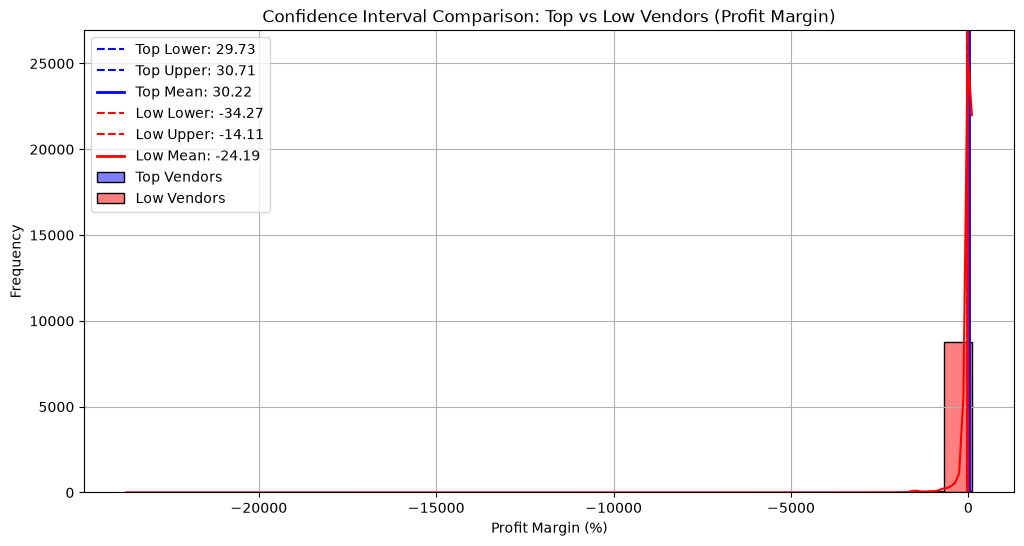

Index(['VendorNumber', 'VendorName', 'Brand', 'Description', 'PurchasePrice',
       'ActualPrice', 'Volume', 'TotalPurchaseQuantity',
       'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesDollars',
       'TotalSalesPrice', 'TotalExciseTax', 'FreightCost', 'GrossProfit',
       'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio'],
      dtype='str')


In [3]:
# Calculate confidence intervals

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine
from scipy import stats
engine = create_engine("sqlite:///inventory.db")

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(df.head())

df.columns = (
df.columns
.str.strip()
.str.replace(" ", "", regex=False)
)
 
print(df.columns)

def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)

    std_err = np.std(data, ddof=1) / np.sqrt(len(data))

    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        len(data) - 1
    )

    margin = t_critical * std_err

    lower = mean_val - margin
    upper = mean_val + margin

    return mean_val, lower, upper
     

top_threshold = df["TotalSalesDollars"].quantile(0.85)

top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()

low_vendors = df[df["TotalSalesDollars"] < top_threshold]["ProfitMargin"].dropna()

top_mean, top_lower, top_upper = confidence_interval(top_vendors)

low_mean, low_lower, low_upper = confidence_interval(low_vendors)

# Print results
print(
    f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), "
    f"Mean: {top_mean:.2f}"
)

print(
    f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), "
    f"Mean: {low_mean:.2f}"
)

# Plot distributions
plt.figure(figsize=(12, 6))

# Top Vendors Plot
sns.histplot(
    top_vendors,
    kde=True,
    color="blue",
    bins=30,
    alpha=0.5,
    label="Top Vendors"
)

plt.axvline(
    top_lower,
    color="blue",
    linestyle="--",
    label=f"Top Lower: {top_lower:.2f}"
)

plt.axvline(
    top_upper,
    color="blue",
    linestyle="--",
    label=f"Top Upper: {top_upper:.2f}"
)

plt.axvline(
    top_mean,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Top Mean: {top_mean:.2f}"
)

# Low Vendors Plot
sns.histplot(
    low_vendors,
    kde=True,
    color="red",
    bins=30,
    alpha=0.5,
    label="Low Vendors"
)

plt.axvline(
    low_lower,
    color="red",
    linestyle="--",
    label=f"Low Lower: {low_lower:.2f}"
)

plt.axvline(
    low_upper,
    color="red",
    linestyle="--",
    label=f"Low Upper: {low_upper:.2f}"
)

plt.axvline(
    low_mean,
    color="red",
    linestyle="-",
    linewidth=2,
    label=f"Low Mean: {low_mean:.2f}"
)

# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

# Clean column names
df.columns = (
    df.columns
      .str.strip()
      .str.replace(" ", "", regex=False)
)

print(df.columns)